*Nombre de Grupos*:

*Integrantes*:

*Dataset elegido*:

# **Tarea 2: Clasificación de imágenes con features y un MLP**

En el Laboratorio 4 armamos un detector de disfraces en dos etapas: una **función de features** que transformaba cada foto en unos pocos números (qué tan naranja, qué tan gordo) y un **perceptrón** que cortaba ese espacio en dos. En esta tarea van a hacer lo mismo, pero en grande y con datos reales:

$$\text{imagen} \;\longrightarrow\; \underbrace{\text{features de color y/o LBP (y las que salgan del EDA)}}_{\text{las arman ustedes}} \;\longrightarrow\; \underbrace{\text{estandarización}}_{\text{Parte 1}} \;\longrightarrow\; \underbrace{\text{MLP}}_{\text{lo entrenan ustedes}} \;\longrightarrow\; \text{clase}$$

Antes de presentar la consigna hay una pieza que nos faltaba y que es clave para que el entrenamiento funcione: la **estandarización**.

## **Imports**

In [1]:
import os
import io
import copy
import time
import zipfile
import urllib.request
import numpy as np
import cv2
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact
from skimage.color import rgb2hsv, rgb2gray
from skimage.feature import local_binary_pattern
from skimage.filters import threshold_otsu
from sklearn.model_selection import train_test_split
from skimage import data as fotos_skimage


import torch
import torch.nn as nn

torch.manual_seed(0)
np.random.seed(0)
NARANJA, VIOLETA, VIOLETA_OSCURO = "darkorange", "mediumpurple", "#3b2d4f"

# **Parte 1: Estandarización**

### **El cortacésped del cementerio 🪦**

El cementerio del pueblo compró un robot cortacésped. Tiene una cámara que mira el piso y tiene que decidir, para cada pedacito de imagen, si está sobre pasto (corta) o sobre el camino de grava (no corta, porque se le rompen las cuchillas).

Para decidirlo usamos lo mismo que en la tarea: **features de textura** y una neurona. Las fotos son reales (vienen incluidas en `scikit-image`). De cada foto cortamos 100 parches de $48 \times 48$ píxeles en lugares al azar, y a cada parche le calculamos dos features:

- $x_1$: **aspereza**, el promedio de $(I_{\text{píxel}} - I_{\text{vecino}})^2$ entre cada píxel y su vecino de la derecha y el de abajo. Si los vecinos son muy distintos da un número grande: con 256 niveles de gris vale **cientos o miles**.
- $x_2$: **fracción de "bordes" del LBP**, la fracción de píxeles cuyo código LBP uniforme invariante a rotación (riu2, $P = 8$, $R = 1$, como en el Laboratorio 3) vale $4$: la mitad del círculo de vecinos es más clara que el centro y la otra mitad más oscura, o sea, el píxel está sobre un **borde**. Es una fracción: vale **entre $0.1$ y $0.25$**.

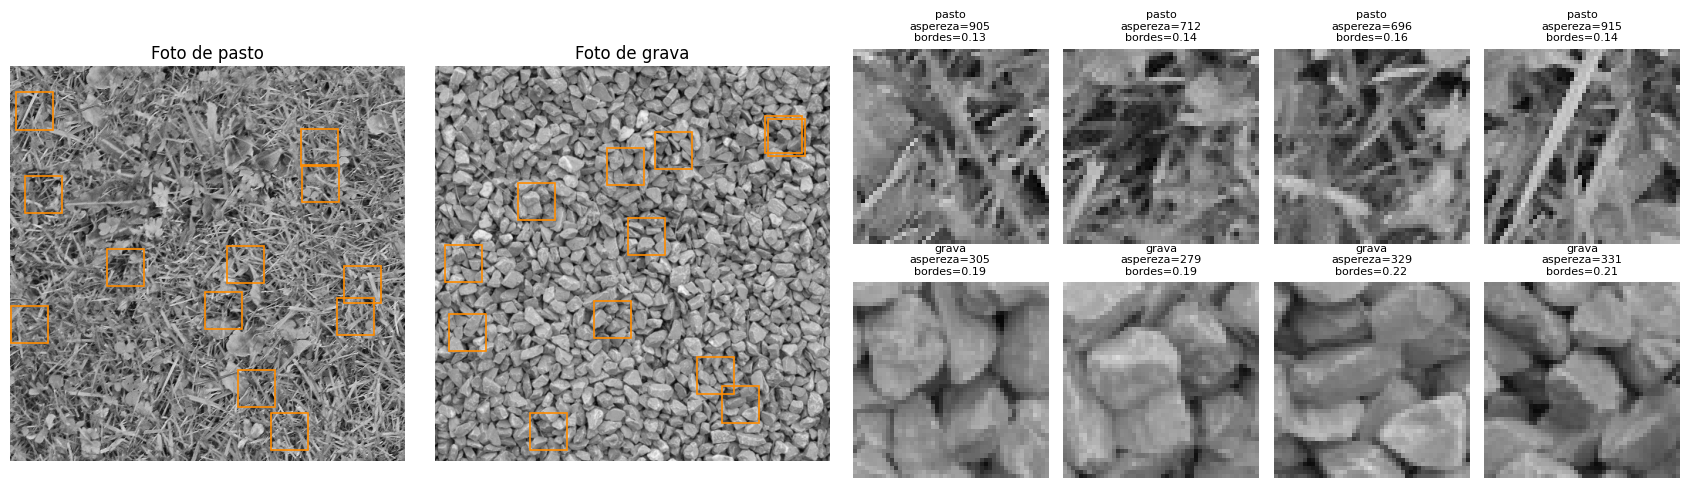

pasto: aspereza entre    444 y   1463,   fracción de bordes LBP entre 0.113 y 0.180
grava: aspereza entre    279 y    546,   fracción de bordes LBP entre 0.174 y 0.248


In [2]:
LADO_PARCHE = 48

def aspereza(parche):
    #Promedio de la diferencia al cuadrado entre cada pixel y su vecino de la derecha y el de abajo
    p = parche.astype(float)
    return (((p[:, 1:] - p[:, :-1]) ** 2).mean() + ((p[1:, :] - p[:-1, :]) ** 2).mean()) / 2

def fraccion_bordes_lbp(parche):
    #Fraccion de pixeles con codigo LBP riu2 = 4 (P = 8, R = 1): mitad de los vecinos mas claros, mitad mas oscuros
    codigos = local_binary_pattern(parche, 8, 1, method="uniform")
    return (codigos == 4).mean()

def cortar_parches(foto, cantidad, rng):
    esquinas = rng.integers(0, foto.shape[0] - LADO_PARCHE, (cantidad, 2))
    return [foto[f:f + LADO_PARCHE, c:c + LADO_PARCHE] for f, c in esquinas], esquinas

rng = np.random.default_rng(0)
foto_pasto, foto_grava = fotos_skimage.grass(), fotos_skimage.gravel()   # fotos reales en escala de grises, 512 x 512
parches_pasto, esquinas_pasto = cortar_parches(foto_pasto, 100, rng)
parches_grava, esquinas_grava = cortar_parches(foto_grava, 100, rng)
X_cesped = np.array([[aspereza(p), fraccion_bordes_lbp(p)] for p in parches_pasto + parches_grava])
y_cesped = np.r_[np.ones(100), np.zeros(100)]   # 1 = pasto (cortar), 0 = grava (no cortar)

fig = plt.figure(figsize=(17, 5))
for k, (foto, esquinas, nombre) in enumerate(((foto_pasto, esquinas_pasto, "pasto"), (foto_grava, esquinas_grava, "grava"))):
    ax = fig.add_subplot(1, 4, k + 1)
    ax.imshow(foto, cmap="gray"); ax.set_title(f"Foto de {nombre}"); ax.axis("off")
    for f, c in esquinas[:12]:
        ax.add_patch(plt.Rectangle((c, f), LADO_PARCHE, LADO_PARCHE, fill=False, ec=NARANJA, lw=1.2))
for k, (parche, nombre) in enumerate([(p, "pasto") for p in parches_pasto[:4]] + [(p, "grava") for p in parches_grava[:4]]):
    ax = fig.add_subplot(2, 8, 5 + (k // 4) * 8 + k % 4)
    ax.imshow(parche, cmap="gray", vmin=0, vmax=255); ax.axis("off")
    x1, x2 = X_cesped[k if k < 4 else 100 + k - 4]
    ax.set_title(f"{nombre}\naspereza={x1:.0f}\nbordes={x2:.2f}", fontsize=8)
plt.tight_layout(); plt.show()

for nombre, X in (("pasto", X_cesped[y_cesped == 1]), ("grava", X_cesped[y_cesped == 0])):
    print(f"{nombre}: aspereza entre {X[:, 0].min():6.0f} y {X[:, 0].max():6.0f},   fracción de bordes LBP entre {X[:, 1].min():.3f} y {X[:, 1].max():.3f}")

Las dos features miden algo de la textura, pero en escalas que no tienen nada que ver: una está en los cientos y la otra en las décimas.

El vector de features de una imagen junta números de todo tipo. Miremos un vector "de verdad" para un parche de pasto, con cosas que vimos en la materia: histogramas, LBP, bordes, Otsu y Fourier.

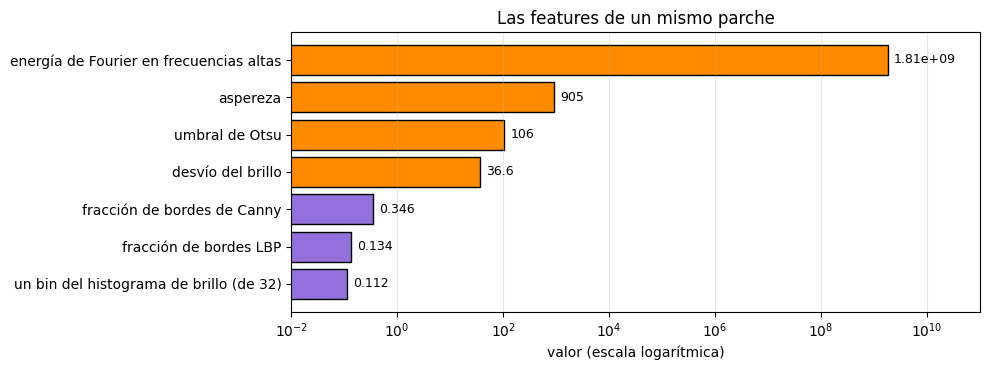

In [3]:
parche = parches_pasto[0]
espectro = np.abs(np.fft.fftshift(np.fft.fft2(parche.astype(float)))) ** 2
yy, xx = np.mgrid[:LADO_PARCHE, :LADO_PARCHE] - LADO_PARCHE // 2
vector = {
    "un bin del histograma de brillo (de 32)": np.histogram(parche, bins=32, range=(0, 256))[0][16] / parche.size,
    "fracción de bordes LBP": fraccion_bordes_lbp(parche),
    "fracción de bordes de Canny": (cv2.Canny(parche, 50, 150) > 0).mean(),
    "desvío del brillo": parche.std(),
    "umbral de Otsu": threshold_otsu(parche),
    "aspereza": aspereza(parche),
    "energía de Fourier en frecuencias altas": espectro[np.hypot(xx, yy) > LADO_PARCHE / 4].sum(),
}
plt.figure(figsize=(10, 3.8))
plt.barh(list(vector), list(vector.values()), color=[VIOLETA if v < 10 else NARANJA for v in vector.values()], edgecolor="k")
for i, v in enumerate(vector.values()):
    plt.text(v * 1.3, i, f"{v:.3g}", va="center", fontsize=9)
plt.xscale("log"); plt.xlim(1e-2, 1e11); plt.xlabel("valor (escala logarítmica)")
plt.title("Las features de un mismo parche"); plt.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()

Entre la feature más chica y la más grande hay **diez órdenes de magnitud**. ¿Le importa eso a la red? Entrenemos una neurona (`nn.Linear(2, 1)`, con la receta de 5 pasos del Laboratorio 4) para el cortacésped, con las dos features tal cual salen:

In [4]:
def entrenar_neurona(X, y, tasa, epocas=300):
    torch.manual_seed(0)
    neurona = nn.Linear(X.shape[1], 1)
    optimizador = torch.optim.SGD(neurona.parameters(), lr=tasa)
    perdida_fn = nn.BCEWithLogitsLoss()
    X_t, y_t = torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32).reshape(-1, 1)
    perdidas = []
    for epoca in range(epocas):
        optimizador.zero_grad()
        perdida = perdida_fn(neurona(X_t), y_t)
        perdida.backward()
        if epoca == 0:
            pendientes = neurona.weight.grad.numpy().ravel().copy()
        optimizador.step()
        perdidas.append(perdida.item())
    with torch.no_grad():
        exactitud = ((neurona(X_t) >= 0).float() == y_t).float().mean().item()
    return perdidas, exactitud, pendientes

for tasa in (1e-2, 1e-4, 1e-6):
    perdidas, exactitud, pendientes = entrenar_neurona(X_cesped, y_cesped, tasa)
    print(f"Tasa {tasa:g}:  pérdida inicial {perdidas[0]:.2f}, final {perdidas[-1]:6.2f},  aciertos {100 * exactitud:.0f}%")
print(f"\nPendientes en el primer paso:  dL/dw_aspereza = {pendientes[0]:.1f},   dL/dw_bordes = {pendientes[1]:.4f}")

Tasa 0.01:  pérdida inicial 2.67, final  74.38,  aciertos 50%
Tasa 0.0001:  pérdida inicial 2.67, final   3.14,  aciertos 50%
Tasa 1e-06:  pérdida inicial 2.67, final   0.56,  aciertos 50%

Pendientes en el primer paso:  dL/dw_aspereza = -430.9,   dL/dw_bordes = -0.0624


**Con ninguna tasa funciona.** Con tasa $0.01$ la pérdida explota y rebota sin parar; con tasas más chicas no explota, pero el robot acierta el $50\%$: dice "pasto" siempre, como si tirara una moneda.

¿Por qué? La respuesta está en el **backpropagation** del Laboratorio 4. Para una neurona con sigmoide y entropía cruzada, la pendiente respecto de cada peso es

$$\frac{\partial L}{\partial w_j} = \text{promedio de } (p - y)\, x_j$$

**La pendiente de cada peso es proporcional a su feature.** Como la aspereza vale **miles de veces** más que la fracción de bordes, su pendiente también es miles de veces más grande (miren los dos números de arriba). El descenso por gradiente da pasos de tamaño $\text{tasa} \times \text{pendiente}$, así que:

- Una tasa que le sirve a la aspereza (muy chica, para no explotar) deja **quietos** al peso de los bordes y al sesgo. El sesgo tendría que llegar a unos cientos para poner el corte entre pasto y grava, y a pasos de $0.000001$ no llega nunca.
- Una tasa que le sirve a la fracción de bordes hace que el peso de la aspereza dé saltos gigantes y la pérdida **explote**.

En el terreno de la pérdida (el de "bajar la pendiente"), una dirección es muchísimo más empinada que la otra: es un valle **larguísimo y finito**, y el descenso rebota de pared a pared.

### **La solución: poner todas las features en la misma escala**

**Estandarizar** una feature es restarle su **media** y dividirla por su **desvío estándar**:

$$x' = \frac{x - \mu}{\sigma}$$

Después de esto, **todas** las features tienen media $0$ y desvío $1$. Un valor $x' = 2$ quiere decir "dos desvíos por encima del promedio", sea una aspereza o una fracción de bordes. Se hace **feature por feature**: cada columna con su propia $\mu$ y su propio $\sigma$. La información no cambia; solo cambian las unidades, como pasar de milímetros a metros.

Media:  aspereza 650.9, bordes 0.1793
Desvío: aspereza 302.2, bordes 0.0409

        crudo, tasa 0.01:  dL/dw_aspereza =  -430.882,  dL/dw_bordes   =  -0.0624
    crudo, tasa 0.000001:  dL/dw_aspereza =  -430.882,  dL/dw_bordes   =  -0.0624
   estandarizado, tasa 1:  dL/dw_aspereza =    -0.473,  dL/dw_bordes   =   0.5558


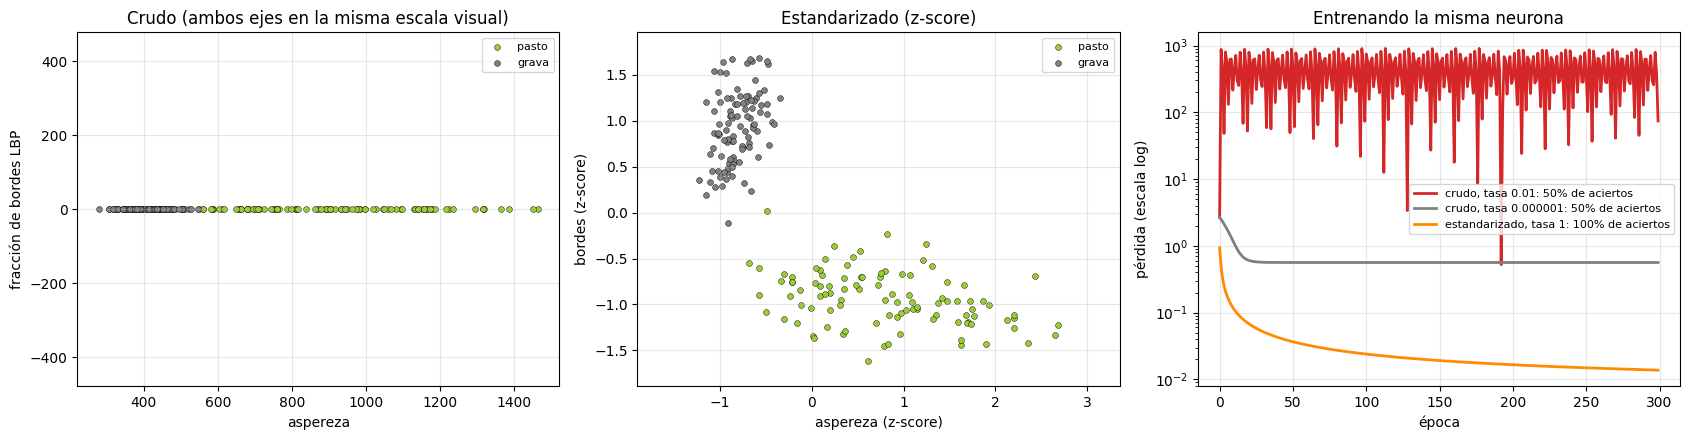

In [5]:
# Estandarización (z-score)
media  = X_cesped.mean(axis=0)
desvio = X_cesped.std(axis=0)

X_cesped_est = (X_cesped - media) / desvio

print(f"Media:  aspereza {media[0]:.1f}, bordes {media[1]:.4f}")
print(f"Desvío: aspereza {desvio[0]:.1f}, bordes {desvio[1]:.4f}\n")

# cruda vs estandarizada
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

paneles = (
    (axes[0], X_cesped,     "Crudo (ambos ejes en la misma escala visual)"),
    (axes[1], X_cesped_est, "Estandarizado (z-score)"),
)
for eje, X, titulo in paneles:
    for clase, nombre, color in ((1, "pasto", "yellowgreen"),
                                 (0, "grava", "gray")):
        eje.scatter(*X[y_cesped == clase].T,
                    c=color, edgecolors="k", linewidths=0.3,
                    s=18, label=nombre)

    eje.set_aspect("equal", adjustable="datalim")
    eje.set_title(titulo)
    eje.legend(fontsize=8)
    eje.grid(alpha=0.3)

axes[0].set_xlabel("aspereza")
axes[0].set_ylabel("fracción de bordes LBP")
axes[1].set_xlabel("aspereza (z-score)")
axes[1].set_ylabel("bordes (z-score)")

#Curvas de pérdida: distintos escalados y tasas de aprendizaje
experimentos = (
    (X_cesped,     1e-2, "crudo, tasa 0.01",      "tab:red"),
    (X_cesped,     1e-6, "crudo, tasa 0.000001",  "tab:gray"),
    (X_cesped_est, 1.0,  "estandarizado, tasa 1", NARANJA),
)
for X, tasa, etiqueta, color in experimentos:
    perdidas, exactitud, pendientes = entrenar_neurona(X, y_cesped, tasa)
    axes[2].plot(perdidas, color=color, lw=2,
                 label=f"{etiqueta}: {100 * exactitud:.0f}% de aciertos")
    print(f"{etiqueta:>24s}:  "
          f"dL/dw_aspereza = {pendientes[0]:9.3f},  "
          f"dL/dw_bordes   = {pendientes[1]:8.4f}")

axes[2].set_yscale("log")
axes[2].set_xlabel("época")
axes[2].set_ylabel("pérdida (escala log)")
axes[2].set_title("Entrenando la misma neurona")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Miren el gráfico de la izquierda: con los ejes en la misma escala, la fracción de bordes es una rayita invisible al lado de la aspereza, y para el descenso por gradiente es igual de invisible. Estandarizando, las dos pendientes quedan del **mismo tamaño**, las dos features "pesan" lo mismo, y la misma neurona acierta casi el $100\%$.

En la tarea pasa exactamente esto, pero con decenas de features en vez de dos: si no estandarizan, el MLP mira casi solo las features grandes (el brillo, un umbral, una energía de Fourier) y los histogramas de color y de LBP quedan ignorados.

### **TIP: la media y el desvío salen solo del entrenamiento**

Los datos se separan en **entrenamiento**, **validación** y **prueba**, como en el Laboratorio 4. La media y el desvío se calculan **solo con el entrenamiento**, y después se aplican esos mismos números a validación, a prueba y a cualquier imagen nueva: al robot, cuando ya está cortando el pasto, le llega de a un parche por vez, y no puede calcular la media de "todos los parches del futuro".

Usar la prueba para calcular la media sería hacer trampa: la prueba simula imágenes que el modelo **nunca vio**, y si su información "se filtra" en el entrenamiento, el resultado queda optimista. Esto se llama **fuga de datos** (*data leakage*).

Por otro lado, si una feature es **constante** en el entrenamiento (por ejemplo, un bin de LBP que siempre vale $0$), su desvío es $0$ y no se puede dividir. En ese caso se usa $\sigma = 1$, la feature queda en $0$.

### ***Ejercicio***: Estandarizar

- Ejercicio: implementar
    - ajustar_estandarizador
    - aplicar_estandarizador

Ayudas:

- `ajustar_estandarizador(X_ent)` recibe solo los datos de entrenamiento (forma `(N, d)`) y devuelve `(media, desvio)`: dos vectores de `d` números, uno por feature (`axis=0`).
- Reemplacen los desvíos que valen $0$ por $1$ con `np.where(desvio < 1e-12, 1.0, desvio)`.
- `aplicar_estandarizador(X, media, desvio)` devuelve `(X - media) / desvio`. El *broadcasting* de numpy se encarga de aplicarlo fila por fila.

In [6]:
def ajustar_estandarizador(X_ent):
    # Devuelve (media, desvio), un valor por feature, calculados SOLO con los datos de entrenamiento
    # COMPLETAR
    raise NotImplementedError("Completar ajustar_estandarizador")


def aplicar_estandarizador(X, media, desvio):
    # COMPLETAR
    raise NotImplementedError("Completar aplicar_estandarizador")

In [7]:
def verificar_estandarizador():
    X_ent = np.array([[1.0, 5.0, 2.0], [3.0, 5.0, 4.0]])
    media, desvio = ajustar_estandarizador(X_ent)
    assert np.allclose(media, [2, 5, 3]), f"[estandarizar] la media por feature es [2, 5, 3], se obtuvo {media}"
    assert np.allclose(desvio, [1, 1, 1]), f"[estandarizar] el desvio es [1, 0 -> 1 (feature constante), 1], se obtuvo {desvio}"
    Z = aplicar_estandarizador(X_ent, media, desvio)
    assert np.allclose(Z, [[-1, 0, -1], [1, 0, 1]]), "[estandarizar] los datos de entrenamiento tienen que quedar con media 0 y desvio 1"
    otro = aplicar_estandarizador(np.array([[2.0, 7.0, 3.0]]), media, desvio)
    assert np.allclose(otro, [[0, 2, 0]]), "[estandarizar] los datos nuevos se transforman con la media y el desvio del ENTRENAMIENTO"
    rng = np.random.default_rng(0)
    grande = rng.normal([0.5, 1500, 80], [0.1, 200, 30], (500, 3))
    Zg = aplicar_estandarizador(grande, *ajustar_estandarizador(grande))
    assert np.allclose(Zg.mean(axis=0), 0, atol=1e-9) and np.allclose(Zg.std(axis=0), 1), "[estandarizar] despues de estandarizar, cada feature tiene media 0 y desvio 1"
    print("OK [estandarizar]")

verificar_estandarizador()

NotImplementedError: Completar ajustar_estandarizador

# **Parte 2: La tarea**

### **Consigna**

Elijan **un** dataset del menú y armen un clasificador de punta a punta:

1. **EDA (análisis exploratorio).** Mirar los datos antes de tocar nada: cuántas imágenes hay por clase, cómo se ven, qué colores y texturas tiene cada clase o lo que USTEDES CREAN NECESARIOS (IGUALMENTE VA A HABER PSITAS PARA QUE SE DEN UNA IDEA). una vez finalizado el EDA, creen sus hipotesis y creen una MLP CHICA O ALGUN ALGORITMO PARA VERIFICARLO. (ES UN PROCESO DE INTERACION DE PRUEBA Y ERROR, DONDE SE CREA ALGORITMO PARA VERIFICAR Y SE VUELVE AL EDA).
Finalmente, se quedan con las hipotesis.
2. **Features.** Programar una función que transforme cada imagen en un vector de números, usando **color**, **LBP** o una **combinación** de los dos: es obligatorio usar al menos uno. Y si en el EDA vieron algo que el color y el LBP no miden, sumen una **feature propia** que lo mida: es la que "sale" del EDA. Qué usar, con qué parámetros y por qué lo deciden ustedes. (POR EJEMPLO, VIMOS QUE LAS TEXTURAS SE PUEDE INVESTIGAR CON FOURIER, ASI QUE CREAMOS UAN FEATURE PARA ESTO...)
3. **Estandarizar** con las funciones de la Parte 1
4. **Entrenar un MLP** en PyTorch, eligiendo la arquitectura con el conjunto de validación. PUEDE SER DER ALTO Y ANCHO QUE QUIERAN.
5. **Evaluar** en el conjunto de prueba y **analizar los errores**.

### **Menú de datasets**

Todos son problemas donde **la textura importa**, pero cada uno a su manera: Puede ser fourier, color, lbp etc...


| Nombre | Clases | De qué se trata | Dataset original |
|---|---|---|---|
| `"histologia"` | 8 tejidos (tumor, estroma, linfocitos, grasa, mucosa, ...) | Cortes de cáncer colorrectal vistos al microscopio | Kather y otros (2016) |
| `"porotos"` | sana, mancha angular, roya | Hojas de poroto fotografiadas en el campo (Uganda). Las enfermedades dejan manchas y pústulas | *beans* (Makerere AI Lab) |
| `"satelite"` | 10 tipos de suelo (bosque, río, autopista, cultivo, residencial, ...) | Imágenes del satélite Sentinel-2 de $64 \times 64$: cultivos, bosques, ciudades y rutas | EuroSAT |
| `"texturas"`  | 8 texturas: cuadriculada, agrietada, con puntos, grilla, panal, rayada, tejida, zigzag | Fotos del *Describable Textures Dataset*. Cada foto se corta en 4 recortes | DTD (Oxford) |


### **Requisitos mínimos**

- [ ] **EDA** con al menos: Mostrar las clases, ejemplos de cada clase, **dos análisis** de color o textura relacionados con las features que van a usar, y la **hipótesis** escrita.
- [ ] **Features** de color y/o LBP, con la elección **justificada** con el EDA.
- [ ] Si el EDA les mostró algo que el color y el LBP no miden: una **feature propia** que lo mida, comparando el modelo **con y sin** ella.
- [ ] **Al menos dos configuraciones de features** comparadas en validación (por ejemplo "solo color" contra "color + LBP"), en una tabla.
- [ ] **Estandarización** con la media y el desvío del entrenamiento.
- [ ] **MLP en PyTorch** de profundidad variable (`crear_modelo` con `capas_ocultas`), entrenado por ustedes, con las **curvas** de entrenamiento y validación.
- [ ] **Al menos 4 arquitecturas** comparadas, con **1, 2 y 3 o más capas ocultas** y distintos anchos, en una tabla con validación, entrenamiento y cantidad de parámetros; la elección justificada.
- [ ] **Resultados en prueba**: exactitud, **matriz de confusión** y **análisis de al menos 4 errores**.
- [ ] **Conclusiones**: ¿se cumplió la hipótesis?
- [ ] **RESPONDER LAS PREGUNTAS FINALES**


No hay una única forma correcta de hacerlo. **Cada dataset pide features distintas**, y la guía de cada uno no les dice qué hacer: les da **pistas** para que lo descubran en el EDA. Lo que se evalúa es que las decisiones estén justificadas con lo que observaron.

# **Parte 3: Los datos**

In [9]:
#@title Elegir y cargar el dataset { display-mode: "form" }
DATASET = "porotos"  #@param ["histologia", "porotos", "satelite", "texturas"]
MAX_POR_CLASE = 300  #@param {type:"integer"}
URL_DATOS = "https://github.com/Elementos-Reconocimiento-Visual-UBA/PracticasERV_2026_4toBim/raw/main/Tarea_2/datos"  #@param {type:"string"}
RUTA_ZIP_PROPIO = ""  #@param {type:"string"}

# Cada dataset es un .zip chico (una carpeta por clase) que la catedra preparo y subio al repositorio de la materia
DATASETS = {
    "porotos":    dict(archivo="porotos.zip", lado=128),
    "satelite":   dict(archivo="satelite.zip", lado=64),
    "histologia": dict(archivo="histologia.zip", lado=128),
    "texturas":   dict(archivo="texturas.zip", lado=128, recortes=2),   # cada foto se corta en 2 x 2 recortes
}
EXTENSIONES = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")
LADO = DATASETS[DATASET]["lado"]


def a_cuadrado(imagen, lado):
    # Recorta el cuadrado central y lo achica a lado x lado
    alto, ancho = imagen.shape[:2]
    m = min(alto, ancho)
    f0, c0 = (alto - m) // 2, (ancho - m) // 2
    recorte = imagen[f0:f0 + m, c0:c0 + m]
    return cv2.resize(recorte, (lado, lado), interpolation=cv2.INTER_AREA if m > lado else cv2.INTER_LINEAR)


def partir(imagen, k):
    # Corta una imagen en k x k recortes iguales
    alto, ancho = imagen.shape[0] // k, imagen.shape[1] // k
    return [imagen[f * alto:(f + 1) * alto, c * ancho:(c + 1) * ancho] for f in range(k) for c in range(k)]


def cargar_de_zip(ruta_zip, maximo, lado, recortes=1):
    # Devuelve (imagenes, etiquetas, nombres_de_clases, grupos). La clase de cada imagen es el nombre de su carpeta.
    # Si recortes > 1, cada foto se corta en recortes x recortes imagenes, y grupos[i] dice de que foto salio la imagen i
    rng = np.random.default_rng(0)
    with zipfile.ZipFile(ruta_zip) as z:
        archivos = [n for n in z.namelist() if n.lower().endswith(EXTENSIONES) and "__MACOSX" not in n]
        clases = sorted({os.path.basename(os.path.dirname(n)) for n in archivos})
        imagenes, etiquetas, grupos = [], [], []
        for indice, clase in enumerate(clases):
            de_la_clase = sorted(n for n in archivos if os.path.basename(os.path.dirname(n)) == clase)
            for nombre in rng.permutation(de_la_clase)[:maximo]:
                imagen = cv2.imdecode(np.frombuffer(z.read(nombre), np.uint8), cv2.IMREAD_COLOR)
                if imagen is None:
                    continue
                numero_de_foto = grupos[-1] + 1 if grupos else 0
                for recorte in partir(a_cuadrado(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB), lado * recortes), recortes):
                    imagenes.append(recorte); etiquetas.append(indice); grupos.append(numero_de_foto)
    return np.array(imagenes), np.array(etiquetas), [c.replace("_", " ") for c in clases], np.array(grupos)


config = DATASETS[DATASET]
if config["archivo"] is not None:
    ruta = config["archivo"]
    if not os.path.exists(ruta):
        print(f"Bajando {ruta} ...")
        urllib.request.urlretrieve(f"{URL_DATOS.rstrip('/')}/{ruta}", ruta)
elif RUTA_ZIP_PROPIO:
    ruta = RUTA_ZIP_PROPIO
else:
    from google.colab import files
    print("Suban un .zip con una carpeta por clase:")
    ruta = next(iter(files.upload()))
imagenes, etiquetas, nombres_clases, grupos = cargar_de_zip(ruta, MAX_POR_CLASE, LADO, config.get("recortes", 1))

N_CLASES = len(nombres_clases)
print(f"Dataset '{DATASET}': {len(imagenes)} imágenes de {LADO}x{LADO} (de {len(np.unique(grupos))} fotos originales), {N_CLASES} clases: {nombres_clases}")

Dataset 'porotos': 900 imágenes de 128x128 (de 900 fotos originales), 3 clases: ['mancha angular', 'roya', 'sana']


In [10]:
#@title Herramientas para graficar (no hace falta leerlas) { display-mode: "form" }
def mostrar_ejemplos(imagenes, etiquetas, nombres_clases, por_clase=6, semilla=None):
    rng = np.random.default_rng(semilla)
    n_clases = len(nombres_clases)
    fig, axs = plt.subplots(n_clases, por_clase, figsize=(1.8 * por_clase, 1.9 * n_clases), squeeze=False)
    for clase in range(n_clases):
        disponibles = np.flatnonzero(etiquetas == clase)
        for j, indice in enumerate(rng.choice(disponibles, min(por_clase, len(disponibles)), replace=False)):
            axs[clase, j].imshow(imagenes[indice])
        for ax in axs[clase]:
            ax.set_xticks([]); ax.set_yticks([])
        axs[clase, 0].set_ylabel(nombres_clases[clase], rotation=0, ha="right", va="center", fontsize=10)
    plt.tight_layout(); plt.show()

def graficar_historial(historial, titulo=""):
    # historial: diccionario con listas "perdida", "exactitud_ent" y "exactitud_val" (una entrada por epoca)
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
    axs[0].plot(historial["perdida"], color=VIOLETA_OSCURO); axs[0].set_xlabel("época"); axs[0].set_ylabel("pérdida de entrenamiento"); axs[0].grid(alpha=0.3)
    axs[1].plot(100 * np.array(historial["exactitud_ent"]), color=NARANJA, label="entrenamiento")
    axs[1].plot(100 * np.array(historial["exactitud_val"]), color=VIOLETA_OSCURO, label="validación")
    axs[1].set_xlabel("época"); axs[1].set_ylabel("exactitud (%)"); axs[1].legend(); axs[1].grid(alpha=0.3)
    plt.suptitle(titulo); plt.tight_layout(); plt.show()

def mostrar_matriz_confusion(y_real, y_pred, nombres_clases, titulo="Matriz de confusión"):
    n = len(nombres_clases)
    M = np.zeros((n, n), int)
    np.add.at(M, (np.asarray(y_real), np.asarray(y_pred)), 1)
    Mn = M / np.maximum(M.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(1.1 * n + 3, 1.0 * n + 2.5))
    ax.imshow(Mn, cmap="Purples", vmin=0, vmax=1)
    for r in range(n):
        for p in range(n):
            ax.text(p, r, f"{M[r, p]}\n{100 * Mn[r, p]:.0f}%", ha="center", va="center", fontsize=8, color="white" if Mn[r, p] > 0.5 else "black")
    ax.set_xticks(range(n)); ax.set_xticklabels(nombres_clases, rotation=35, ha="right")
    ax.set_yticks(range(n)); ax.set_yticklabels(nombres_clases)
    ax.set_xlabel("predicha"); ax.set_ylabel("real"); ax.set_title(titulo)
    plt.tight_layout(); plt.show()
    return M

def mostrar_errores(imagenes, y_real, probabilidades, nombres_clases, cantidad=12):
    # Muestra las imagenes mal clasificadas, empezando por las que el modelo estaba mas seguro
    y_pred = probabilidades.argmax(axis=1)
    errores = np.flatnonzero(y_pred != y_real)
    errores = errores[np.argsort(-probabilidades[errores].max(axis=1))][:cantidad]
    if len(errores) == 0:
        print("¡No hay errores!"); return
    columnas = 6
    filas = int(np.ceil(len(errores) / columnas))
    fig, axs = plt.subplots(filas, columnas, figsize=(2.5 * columnas, 3 * filas), squeeze=False)
    for ax in axs.ravel():
        ax.axis("off")
    for ax, i in zip(axs.ravel(), errores):
        ax.imshow(imagenes[i])
        ax.set_title(f"real: {nombres_clases[y_real[i]]}\ndijo: {nombres_clases[y_pred[i]]} ({100 * probabilidades[i].max():.0f}%)", fontsize=9)
    plt.tight_layout(); plt.show()

# **Parte 4: EDA**

Arrancamos con lo básico. Las dos celdas que siguen ya están hechas; **el resto del EDA lo arman ustedes**.

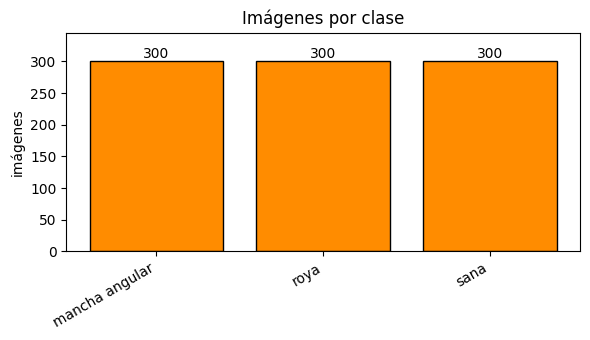

In [11]:
conteo = np.bincount(etiquetas, minlength=N_CLASES)
plt.figure(figsize=(max(6, 1.1 * N_CLASES), 3.5))
plt.bar(nombres_clases, conteo, color=NARANJA, edgecolor="k")
for i, c in enumerate(conteo):
    plt.text(i, c, str(c), ha="center", va="bottom")
plt.ylim(0, 1.15 * conteo.max()); plt.xticks(rotation=30, ha="right"); plt.ylabel("imágenes"); plt.title("Imágenes por clase")
plt.tight_layout(); plt.show()

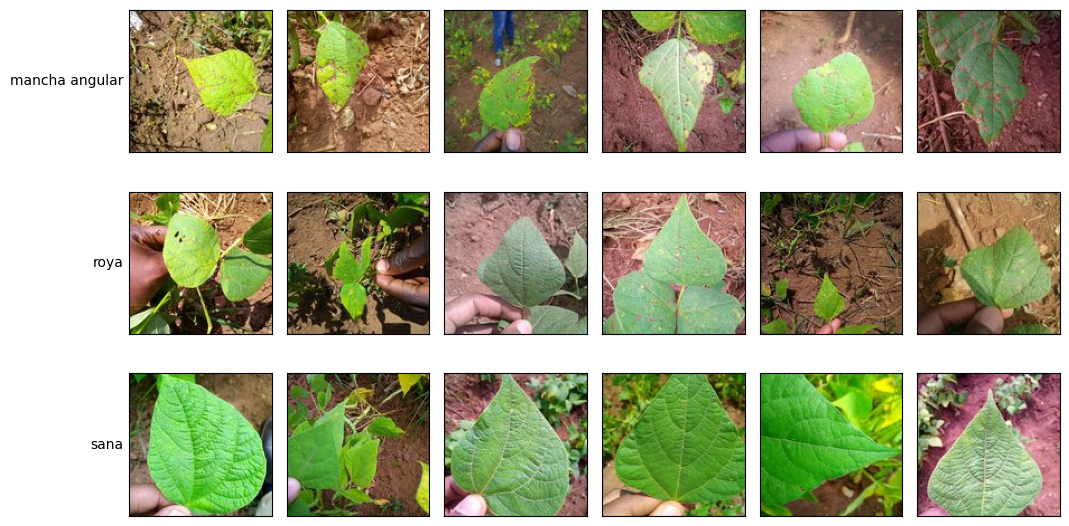

In [14]:
mostrar_ejemplos(imagenes, etiquetas, nombres_clases)   #corran esta celda varias veces: muestra imagenes distintas

### **La guía de su dataset**

Cada dataset tiene su propia guía: de qué se trata, **pistas** para el EDA (no les dice qué hacer, les dice dónde mirar) y **dos preguntas** que tienen que responder en las Conclusiones. La celda que sigue la baja del repositorio de la materia y la muestra acá.

In [ ]:
#@title Mostrar la guía de EDA del dataset elegido { display-mode: "form" }
URL_GUIAS = "https://github.com/Elementos-Reconocimiento-Visual-UBA/PracticasERV_2026_4toBim/raw/main/Tarea_2/guias"  #@param {type:"string"}
from IPython.display import Markdown, display

try:
    with urllib.request.urlopen(f"{URL_GUIAS.rstrip('/')}/{DATASET}.md", timeout=30) as respuesta:
        display(Markdown(respuesta.read().decode("utf-8")))
except Exception as error:
    print(f"No se pudo bajar la guía ({error}).")
    print(f"Pueden leerla en: {URL_GUIAS.rstrip('/').replace('/raw/', '/blob/')}/{DATASET}.md")

### **Su EDA**

Empiecen por las **pistas de la guía** de su dataset. Además, estas preguntas sirven para cualquier dataset (no hace falta responderlas)

- **Color:** ¿cuál es el color promedio de cada clase? ¿Cómo son los histogramas de **tono** (H) y **saturación** (S) por clase? ¿El brillo (V) cambia mucho dentro de una clase (iluminación)?
- **Textura:** ¿cómo se ve el mapa LBP de un ejemplo de cada clase? ¿Cómo es el histograma LBP **promedio** de cada clase? ¿Cambia la diferencia entre clases si usan otro radio $R$?
- **Forma y regiones:** si umbralizan (por ejemplo con Otsu), ¿qué queda de cada clase? ¿Cuántas regiones aparecen y de qué tamaño?
- **Los datos en sí:** ¿hay imágenes raras, repetidas, mal etiquetadas o con fondos que delaten la clase?

Herramientas útiles:

```python
hsv = rgb2hsv(imagen)
gris = (rgb2gray(imagen) * 255).astype(np.uint8)
codigos = local_binary_pattern(gris, 8, 1, method="uniform")   # mapa LBP riu2: valores de 0 a P+1
codigos = local_binary_pattern(gris, 16, 2, method="uniform")  # otra escala: P = 16 vecinos a radio R = 2
mascara = gris > threshold_otsu(gris) # umbralizar con Otsu (Laboratorio 2)
n, etiquetas_regiones, stats, _ = cv2.connectedComponentsWithStats(mascara.astype(np.uint8))   # regiones conexas; stats[1:, cv2.CC_STAT_AREA] = areas
espectro = np.abs(np.fft.fftshift(np.fft.fft2(gris))) ** 2   # Fourier: energia por frecuencia (en el centro, las frecuencias bajas)
bordes = cv2.Canny(gris, 50, 150) # bordes
lineas = cv2.HoughLinesP(bordes, 1, np.pi / 180, threshold=40, minLineLength=20, maxLineGap=3)  # segmentos rectos (Hough), o None
imagenes[etiquetas == c]  # todas las imagenes de la clase c
```

### EJEMPLO DE UN POSIBLE EDA

idea simple: inventar una medida, calcularla en todas las imágenes y mirar si cambia según la clase.

1) Mirar unas imágenes de cada clase y sospechar algo (“las plantas enfermas tienen manchas”).

2) Convertir esa sospecha en un número por imagen, con una función: cuántas manchas, cuánto naranja, cuánta energía de Fourier, cuántas líneas de Hough.

3) Compararlo por clase con un diagrama de caja o un histograma. Si las cajas quedan separadas, esa medida distingue las clases y es candidata a feature. Si se pisan, no sirve.




```
# 1) Una medida candidata: umbralizo con Otsu (Laboratorio 2) y cuento las regiones oscuras.
def contar_manchas(imagen, area_minima):

# 2) Ver qué mide, en una imagen de cada clase
fig, axs = plt.subplots(2, N_CLASES, figsize=(2.2 * N_CLASES, 4.6))
for c in range(N_CLASES):...

# 3) Calcularla en TODAS las imágenes y comparar por clase
manchas = np.array([contar_manchas(im) for im in imagenes])

```

O sacar un valor numerico y probarlo en una mini MLP para ver que onda u otro algoritmo.



In [19]:
from IPython.display import HTML, display

url_img = "https://raw.githubusercontent.com/Elementos-Reconocimiento-Visual-UBA/PracticasERV_2026_4toBim/main/Tarea_2/ejemplo.webp"

display(HTML(f'<img src="{url_img}" height= "800" width="800">'))

In [ ]:
# === SU EDA ===
# Agreguen aca (y en las celdas que quieran) sus analisis de color y textura


#

### **Observaciones e hipótesis**

*Escriban acá lo que observaron e hipótesis: "Creemos que lo que más distingue las clases es ___, porque ___. Esperamos que las clases ___ y ___ se confundan entre sí."*

Por ejemplo:

**Ejemplo: ladrillo / pasto / grava**

El **ladrillo es liso**: solo el 8% de sus píxeles son borde de Canny, contra 30–35% en el pasto y la grava. Con esa sola medida ya se llega al 94% de exactitud.

El **pasto tiene muchas manchas oscuras** (las sombras entre las hojas): unas 18 manchas de Otsu por imagen, contra 4–6 en las otras dos clases. Sola, esta medida llega solo al 77%, porque no distingue el ladrillo de la grava. Pero junto con los bordes llega al 98%: cada medida resuelve lo que la otra no puede.

El **brillo medio** se pisa en el boxplot (el pasto queda en el medio de las otras dos) y solo da 76%. Sin embargo, sumado a las otras dos medidas lleva al 99%: una medida que no alcanza sola puede aportar en combinación.

**Confusión esperada:** pasto ↔ grava. Las dos tienen muchos bordes, y lo que las separa son las manchas.

# **Parte 5: Features**

Programen la función `extraer_features(imagen)`, que recibe una imagen RGB (`uint8`, forma `(LADO, LADO, 3)`) y devuelve **un vector de números**: siempre del mismo largo, sin `NaN`.
PUEDE SER  `extraer_LBP(imagen)`, `extraer_COLOR_HSV(imagen)`, `extraer_combinacion(imagen)`, `extraer_x_cosa(imagen)`

LES VAS A SERVIR Y ES REQUERIDO AL MENOS PROGRMAR ALGUNA DE LAS SIGUIETNES FUNCIONES (COLOR, LBP, O FEATURE PROPIA)

**Color.** Histogramas normalizados de los canales de HSV (por ejemplo, $16$ bins de H y $8$ de S), estadísticas por canal (media, desvío), o el color promedio. Recuerden que H y S dependen poco de la iluminación y V depende mucho.

**LBP.** El histograma normalizado del mapa LBP uniforme invariante a rotación (`method="uniform"`, $P + 2$ bins), en una o varias escalas $(P, R)$, por ejemplo $(8, 1)$, $(16, 2)$ y $(24, 3)$. Describe la textura a nivel de patrones locales (bordes, puntos, zonas planas) y es invariante a la iluminación (Laboratorio 3).

**Feature propia (la que sale del EDA).** Si en el EDA vieron algo que distingue las clases y que el color y el LBP no miden, conviértanlo en un número. Herramientas de la materia que pueden servir:

- **Fourier**: la energía del espectro en **anillos** (cuánta textura fina o gruesa hay) o en **sectores** (en qué orientación van las rayas). Muy útil para texturas periódicas como rayas, cuadriculados o tejidos.
- **Hough**: la cantidad, el largo o la orientación de las líneas rectas que encuentra (`cv2.HoughLinesP` sobre los bordes de Canny). Útil para rayones, grietas o rutas.
- **Bordes**: la fracción de píxeles que son borde (Canny), o la intensidad media del gradiente (Sobel).
- **Color específico**: la fracción de píxeles en cierto rango de HSV.
- **Umbralización** (Laboratorio 2): el umbral de Otsu, la fracción de píxeles que quedan de un lado, o la cantidad y el tamaño de las regiones que quedan después de umbralizar (`cv2.connectedComponentsWithStats`).
- **Diferencias entre vecinos**: el promedio de $(I_{\text{píxel}} - I_{\text{vecino}})^2$, como la "aspereza" de la Parte 1, calculado en distintas direcciones o distancias.

Pueden usar `skimage` (`local_binary_pattern`, `rgb2hsv`, `threshold_otsu`) o sus propias implementaciones de los laboratorios.

Para poder comparar configuraciones, conviene que `extraer_features` reciba **qué familias usar** como parámetro. La celda de abajo sugiere una forma de organizarlo, pero pueden cambiarla.

In [ ]:
#POR EJEMPLO

def extraer_features(imagen, usar_color=True, usar_lbp=True, usar_propia=False):
    # Devuelve un vector 1D de floats (siempre del mismo largo para la misma configuracion)
    partes = []
    gris = (rgb2gray(imagen) * 255).astype(np.uint8)
    # COMPLETAR: agregar a `partes` los pedazos de vector de cada familia que usen
    # (opcional) si usar_propia es True, agregar su feature propia
    if not partes:
        raise ValueError("Hay que usar al menos una familia de features")
    return np.concatenate([np.ravel(p) for p in partes]).astype(float)

In [ ]:
def verificar_features():
    rng = np.random.default_rng(0)
    pruebas = [imagenes[0], imagenes[-1], np.zeros((LADO, LADO, 3), np.uint8), rng.integers(0, 256, (LADO, LADO, 3)).astype(np.uint8)]
    vectores = [extraer_features(im) for im in pruebas]
    for v in vectores:
        assert v.ndim == 1, f"[features] tiene que devolver un vector 1D, devolvio forma {v.shape}"
        assert len(v) == len(vectores[0]), "[features] todas las imagenes tienen que dar vectores del mismo largo"
        assert np.isfinite(v).all(), "[features] hay NaN o infinitos (¿una division por cero? ¿una imagen toda negra?)"
    assert not np.allclose(vectores[0], vectores[3]), "[features] dos imagenes muy distintas dan el mismo vector: ¿las features miran la imagen?"
    print(f"OK [features] vectores de {len(vectores[0])} números, sin NaN")

verificar_features()

### **Calcular las features de todo el dataset**

La celda arma la matriz de features para cada **configuración** que quieran comparar. Editen el diccionario `CONFIGURACIONES` (pueden agregar las que quieran, por ejemplo una con su feature propia).

In [ ]:
#ES TOTALMENTE OPCIONAL, SIRVE PARA VER EL TAMAÑO DE SU MATRIZ, EL TIEMPO QUE DURO EN EXTRAER LAS FEATURES ETC....
# UN OUTPUT DE SALIDA ES POR EJEMPLO color + LBP: matriz (1200, 34) en 4.0 s
CONFIGURACIONES = {
    "solo color":     dict(usar_color=True, usar_lbp=False),
    "solo LBP":       dict(usar_color=False, usar_lbp=True),
    "color + LBP":    dict(usar_color=True, usar_lbp=True),
    # "color + LBP + propia": dict(usar_color=True, usar_lbp=True, usar_propia=True),
}

FEATURES = {}
for nombre, opciones in CONFIGURACIONES.items():
    inicio = time.perf_counter()
    FEATURES[nombre] = np.array([extraer_features(im, **opciones) for im in imagenes])
    print(f"{nombre:>22s}: matriz {FEATURES[nombre].shape} en {time.perf_counter() - inicio:.1f} s")

**Justificación de las features elegidas** (relaciónenla con el EDA):

*Respuesta:*

# **Parte 6: Entrenamiento**

### **Entrenamiento, validación y prueba**

La partición ya está hecha y es **estratificada** (cada parte tiene la misma proporción de cada clase): $70\%$ para entrenar, $15\%$ para validar y $15\%$ para la prueba final. Usen **los mismos índices** para todas las configuraciones, así la comparación es justa. **La prueba no se toca hasta la Parte 7.**

Un detalle: en el dataset de texturas cada foto se cortó en 4 recortes. Los recortes de una misma foto se parecen muchísimo, así que si uno quedara en entrenamiento y otro en prueba, el modelo "ya lo habría visto": sería **fuga de datos**. Por eso la partición se hace **por foto original** (la variable `grupos`): los recortes de una foto van siempre juntos al mismo conjunto.

In [15]:
# Partimos las FOTOS ORIGINALES (no las imagenes), para que los recortes de una foto queden siempre juntos
fotos, primera = np.unique(grupos, return_index=True)
clase_de_foto = etiquetas[primera]
f_ent, f_resto, _, c_resto = train_test_split(fotos, clase_de_foto, test_size=0.30, stratify=clase_de_foto, random_state=0)
f_val, f_prueba = train_test_split(f_resto, test_size=0.50, stratify=c_resto, random_state=0)
i_ent, i_val, i_prueba = (np.flatnonzero(np.isin(grupos, f)) for f in (f_ent, f_val, f_prueba))
print(f"Entrenamiento: {len(i_ent)}, validación: {len(i_val)}, prueba: {len(i_prueba)}")

def preparar(X):
    # Estandariza con la media y el desvio del ENTRENAMIENTO y devuelve los tensores de las tres partes
    media, desvio = ajustar_estandarizador(X[i_ent])
    a_tensor = lambda A: torch.tensor(aplicar_estandarizador(A, media, desvio), dtype=torch.float32)
    return a_tensor(X[i_ent]), a_tensor(X[i_val]), a_tensor(X[i_prueba]), (media, desvio)

y_ent, y_val, y_prueba = (torch.tensor(etiquetas[i], dtype=torch.long) for i in (i_ent, i_val, i_prueba))

Entrenamiento: 630, validación: 135, prueba: 135


### **El MLP y su entrenamiento**

Escriban:

- `crear_modelo(n_entrada, n_clases, capas_ocultas)`: un MLP **de cualquier profundidad**. `capas_ocultas` es una tupla con la cantidad de neuronas de cada capa oculta: `(64,)` es una sola capa oculta de $64$ neuronas, y `(256, 128, 64)` son tres capas ocultas, de $256$, $128$ y $64$. Cada capa oculta es un `nn.Linear` seguido de un `nn.ReLU()`. Como en el Laboratorio 4, la red termina en una capa con una salida por clase y sin softmax (la aplica `nn.CrossEntropyLoss`).
- `exactitud(modelo, X, y)`: la fracción de aciertos, como `float`.
- `entrenar(modelo, X_ent, y_ent, X_val, y_val, ...)`: el bucle de entrenamiento. Tiene que devolver un diccionario `historial` con tres listas, una entrada por época: `"perdida"` (la pérdida promedio de entrenamiento), `"exactitud_ent"` y `"exactitud_val"`. Así lo pueden graficar con `graficar_historial`.

Ayudas para `crear_modelo`:

- Armen una lista `capas = []` y recorran `capas_ocultas` con un `for`: en cada paso agreguen `nn.Linear(n_anterior, n)` y `nn.ReLU()`, y actualicen `n_anterior = n` (arranca en `n_entrada`).
- Al final agreguen la capa de salida `nn.Linear(n_anterior, n_clases)` y devuelvan `nn.Sequential(*capas)`.

Sugerencias para `entrenar`:

- El optimizador **Adam** (`torch.optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-4)`) suele andar bien sin tunear mucho. El `weight_decay` es la regularización L2 del Laboratorio 4.
- Recorran los datos **de a lotes** (por ejemplo de $32$): en cada época, `orden = torch.randperm(len(X_ent))` y después `orden[inicio:inicio + tam_lote]`.
- **Quédense con la mejor época en validación**: si la exactitud de validación es la mejor hasta ahora, guarden una copia de los pesos con `copy.deepcopy(modelo.state_dict())`, y al final cárguenla con `modelo.load_state_dict(...)`. Así, si el modelo empieza a sobreajustar, se quedan con la versión de antes.

EJEMPLO

```python
optimizador = torch.optim.Adam(modelo.parameters(), lr=tasa, weight_decay=weight_decay)
perdida_fn = nn.CrossEntropyLoss()
mejor_val = -1                                  # la mejor exactitud de validación vista hasta ahora
mejores_pesos = copy.deepcopy(modelo.state_dict())

for epoca in range(epocas):
    modelo.train()
    orden = torch.randperm(len(X_ent))          # mezcla los índices: [ 7, 152, 3, 41, ... ]
    perdidas_del_epoca = []
    for inicio in range(0, len(X_ent), tam_lote):     # inicio = 0, 32, 64, ...
        lote = orden[inicio:inicio + tam_lote]        # 32 índices al azar
        # ... los 4 pasos de siempre con X_ent[lote] y y_ent[lote]:
        #     zero_grad, perdida, backward, step
        # ... y guardar perdida.item() en perdidas_del_epoca

    # al final de cada época: anotar en el historial
    # ... historial["perdida"]       ← el promedio de perdidas_del_epoca
    # ... historial["exactitud_ent"] ← exactitud(modelo, X_ent, y_ent)
    # ... historial["exactitud_val"] ← exactitud(modelo, X_val, y_val)

    # ... si la exactitud de validación de esta época supera a mejor_val:
    #     actualizar mejor_val y guardar mejores_pesos = copy.deepcopy(modelo.state_dict())

modelo.load_state_dict(mejores_pesos)           # nos quedamos con la mejor época, no con la última
```

In [ ]:
def crear_modelo(n_entrada, n_clases, capas_ocultas=(128, 64)):
    # capas_ocultas: neuronas de cada capa oculta, por ejemplo (64,) o (256, 128, 64)
    # COMPLETAR
    capas = []
    n_anterior = n_entrada                 # lo que entra a la primera capa
    for n in capas_ocultas:
        # COMPLETAR: agregar a `capas` una nn.Linear de n_anterior a n, y un nn.ReLU()
        # COMPLETAR: actualizar n_anterior (la próxima capa recibe lo que sale de esta)
        pass
    # COMPLETAR: agregar la capa de salida (una neurona por clase, SIN ReLU)
    raise NotImplementedError("Completar crear_modelo")


def contar_parametros(modelo):
    # Cantidad de pesos y sesgos que se entrenan
    return sum(p.numel() for p in modelo.parameters())


def exactitud(modelo, X, y):
    # COMPLETAR
    modelo.eval()                          # modo evaluación
    with torch.no_grad():                  # no hace falta calcular gradientes
        # COMPLETAR: la clase predicha es la salida más grande (argmax en dim=1).
        # Comparar con y y devolver la fracción de aciertos como float (.float().mean().item())
    raise NotImplementedError("Completar exactitud")


def entrenar(modelo, X_ent, y_ent, X_val, y_val, epocas=100, tasa=1e-3, tam_lote=32, weight_decay=1e-4):
    historial = {"perdida": [], "exactitud_ent": [], "exactitud_val": []}
    optimizador = torch.optim.Adam(modelo.parameters(), lr=tasa, weight_decay=weight_decay)
    perdida_fn = nn.CrossEntropyLoss()
    mejor_val = -1.0
    mejores_pesos = copy.deepcopy(modelo.state_dict())

    for epoca in range(epocas):
        modelo.train()
        orden = torch.randperm(len(X_ent))             # los índices mezclados
        perdidas = []
        for inicio in range(0, len(X_ent), tam_lote):
            lote = orden[inicio:inicio + tam_lote]     # tam_lote índices al azar
            # COMPLETAR: los 4 pasos de siempre (Laboratorio 4), usando X_ent[lote] y y_ent[lote]
            #   1) borrar los gradientes viejos
            #   2) calcular la pérdida
            #   3) backward
            #   4) un paso del optimizador
            # y guardar perdida.item() en `perdidas`
            pass

        # COMPLETAR: anotar esta época en el historial
        #   "perdida"       -> el promedio de `perdidas`
        #   "exactitud_ent" -> exactitud en entrenamiento
        #   "exactitud_val" -> exactitud en validación

        # COMPLETAR: si la exactitud de validación de esta época supera a mejor_val,
        #   actualizar mejor_val y guardar una COPIA de los pesos (copy.deepcopy(modelo.state_dict()))

    modelo.load_state_dict(mejores_pesos)              # nos quedamos con la mejor época, no con la última
    return historial

In [ ]:
def verificar_entrenamiento():
    torch.manual_seed(0)
    X = torch.randn(300, 5); y = (X[:, 0] > 0).long() + (X[:, 1] > 1).long()
    for capas in ((8,), (16, 8), (32, 16, 8, 4)):
        m = crear_modelo(5, 3, capas)
        assert m(X[:4]).shape == (4, 3), f"[modelo] con capas_ocultas={capas}, 4 ejemplos y 3 clases la salida tiene que ser (4, 3)"
        lineales = [c for c in m.modules() if isinstance(c, nn.Linear)]
        assert len(lineales) == len(capas) + 1, f"[modelo] con capas_ocultas={capas} tiene que haber {len(capas) + 1} capas nn.Linear (una por capa oculta y la de salida), hay {len(lineales)}"
        assert [l.out_features for l in lineales] == list(capas) + [3], f"[modelo] las capas tienen que tener {list(capas) + [3]} neuronas"
        assert sum(isinstance(c, nn.ReLU) for c in m.modules()) == len(capas), "[modelo] tiene que haber un ReLU despues de cada capa oculta (y no despues de la salida)"
    modelo = crear_modelo(5, 3, (16, 8))
    historial = entrenar(modelo, X[:200], y[:200], X[200:], y[200:], epocas=40)
    assert set(historial) >= {"perdida", "exactitud_ent", "exactitud_val"} and len(historial["perdida"]) == 40, "[entrenar] el historial tiene que tener las 3 listas con una entrada por epoca"
    assert historial["perdida"][-1] < historial["perdida"][0], "[entrenar] la perdida tiene que bajar"
    assert isinstance(exactitud(modelo, X, y), float), "[exactitud] tiene que devolver un float"
    assert max(historial["exactitud_val"]) > 0.8, f"[entrenar] en un problema facil tendria que pasar el 80% en validacion, llego a {100 * max(historial['exactitud_val']):.0f}%"
    print(f"OK [entrenar] mejor validación {100 * max(historial['exactitud_val']):.0f}%")

verificar_entrenamiento()

### **Comparar configuraciones de features**

Entrenamos el mismo MLP con cada configuración y comparamos la **mejor exactitud en validación**. (Fíjense que la estandarización se hace adentro de `preparar`, con los datos de entrenamiento de cada configuración.)

In [ ]:
#COMPLETAR
resultados = {}
for nombre, X in FEATURES.items():
    X_ent, X_val, X_prueba, _ = preparar(X)      # estandariza con la media y el desvío del ENTRENAMIENTO

    torch.manual_seed(0)                         # mismos pesos iniciales para todas: la comparación es justa
    # COMPLETAR: crear un modelo NUEVO (¿cuántas entradas tiene? depende de X) y entrenarlo 100 épocas
    # COMPLETAR: guardar en resultados[nombre] la mejor exactitud en validación del historial

    print(f"{nombre:>22s}: {X.shape[1]:3d} features, mejor validación {100 * resultados[nombre]:.1f}%")

**Tabla de configuraciones** (completen con sus números y comenten: ¿qué familia aporta más en su dataset? ¿Coincide con la hipótesis?):

| Configuración | Cantidad de features | Mejor exactitud en validación |
|---|---|---|
| | | |

### **Elegir la arquitectura: ancho y profundidad**

En el Laboratorio 4 vimos que cada capa oculta **transforma el espacio**: una red más **profunda** puede encadenar más transformaciones, y una más **ancha** tiene más neuronas en cada una.

Con la configuración de features que eligieron, prueben **al menos cuatro** arquitecturas que cambien la **profundidad** (como mínimo una de $1$, una de $2$ y una de $3$ o más capas ocultas) y también el **ancho**. Por ejemplo:

| Arquitectura | `capas_ocultas` |
|---|---|
| 1 capa oculta | `(64,)` |
| 2 capas ocultas | `(128, 64)` |
| 3 capas ocultas | `(256, 128, 64)` |
| 4 capas ocultas, angostas | `(32, 32, 32, 32)` |

Para cada una miren las curvas y anoten la mejor exactitud en validación, la cantidad de parámetros (`contar_parametros`) y la **diferencia entre entrenamiento y validación** (si es grande, hay sobreajuste). Al final, un gráfico de exactitud en validación contra cantidad de parámetros ayuda a ver si "más grande" es "mejor".

In [ ]:
CONFIGURACION_ELEGIDA = "color + LBP"   # elijan segun la tabla

X_ent, X_val, X_prueba, estandarizador = preparar(FEATURES[CONFIGURACION_ELEGIDA])
# COMPLETAR: entrenar al menos 4 arquitecturas (1, 2 y 3 o mas capas ocultas, y distintos anchos),
# graficar sus historiales, armar la tabla (validacion, entrenamiento, parametros) y guardar la elegida en `modelo_final`
modelo_final = None

In [ ]:
CONFIGURACION_ELEGIDA = "color + LBP"   # COMPLETAR: elijan según la tabla de configuraciones
X_ent, X_val, X_prueba, estandarizador = preparar(FEATURES[CONFIGURACION_ELEGIDA])

# COMPLETAR: al menos 4 arquitecturas, con 1, 2 y 3 o más capas ocultas, y variando el ancho. PUEDEN VARIAR COMO QUEIRAN
ARQUITECTURAS = [(64,), (128, 64), (256, 128, 64), (32, 32, 32, 32)]

modelos, tabla_arquitecturas = {}, []
for capas in ARQUITECTURAS:
    torch.manual_seed(0)
    # COMPLETAR: crear el modelo con estas capas ocultas, guardarlo en modelos[capas] y entrenarlo 100 épocas
    # COMPLETAR: buscar la MEJOR época en validación (np.argmax) y armar la fila con lo que pasó EN ESA ÉPOCA:
    fila = dict(capas=capas,
                profundidad=...,     # cantidad de capas ocultas
                parametros=...,      # contar_parametros
                val=...,             # exactitud de validación en la mejor época
                ent=...)             # exactitud de entrenamiento en esa misma época
    tabla_arquitecturas.append(fila)
    graficar_historial(historial, f"capas ocultas {capas}: mejor validación {100 * fila['val']:.1f}%")

#De acá para abajo ya está hecho: muestra la tabla y el gráfico...
print(f"{'capas ocultas':>22s} {'prof.':>5s} {'parámetros':>10s} {'val':>6s} {'ent':>6s} {'ent - val':>9s}")
for f in tabla_arquitecturas:
    print(f"{str(f['capas']):>22s} {f['profundidad']:5d} {f['parametros']:10d} {100 * f['val']:5.1f}% {100 * f['ent']:5.1f}% {100 * (f['ent'] - f['val']):8.1f}%")

plt.figure(figsize=(7, 4))
for f in tabla_arquitecturas:
    plt.scatter(f["parametros"], 100 * f["val"], s=60, c=[plt.cm.viridis(f["profundidad"] / 4)], edgecolors="k")
    plt.annotate(str(f["capas"]), (f["parametros"], 100 * f["val"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.xscale("log"); plt.xlabel("cantidad de parámetros (escala log)"); plt.ylabel("mejor exactitud en validación (%)")
plt.title("¿Más grande es mejor?"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Tabla de arquitecturas y elección.** Completen la tabla y respondan: ¿agregar capas mejoró la validación? ¿A partir de qué tamaño empieza a sobreajustar? ¿Por qué eligieron esa arquitectura?

| `capas_ocultas` | Profundidad | Parámetros | Mejor validación | Entrenamiento en esa época | Diferencia |
|---|---|---|---|---|---|
| | | | | | |

*Respuesta:*

# **Parte 7: Resultados**

Recién ahora, con todas las decisiones tomadas, miramos el conjunto de **prueba**.

In [ ]:
print(f"Exactitud en PRUEBA: {100 * exactitud(modelo_final, X_prueba, y_prueba):.1f}%   (azar: {100 / N_CLASES:.1f}%)")
modelo_final.eval()
with torch.no_grad():
    probabilidades_prueba = torch.softmax(modelo_final(X_prueba), dim=1).numpy()
y_real_prueba = y_prueba.numpy()
M_prueba = mostrar_matriz_confusion(y_real_prueba, probabilidades_prueba.argmax(axis=1), nombres_clases, "Matriz de confusión en prueba")

### **Análisis de errores**

Las imágenes de prueba mal clasificadas, empezando por las que el modelo estaba **más seguro** (los errores más "confiados"). Elijan **al menos cuatro** y expliquen por qué creen que se equivocó: ¿es ambigua? ¿está mal etiquetada? ¿tiene un fondo o una iluminación rara? ¿Una persona también dudaría?

In [ ]:
mostrar_errores(imagenes[i_prueba], y_real_prueba, probabilidades_prueba, nombres_clases)

*Análisis de los errores:*

### **Extra: una foto propia**

Saquen una foto de algo de su dataset (una fruta de su casa, una hoja, el cielo, una pared con una grieta, granos de café) y súbanla. Se le aplica **exactamente** el mismo procesamiento: recorte cuadrado, achicado a `LADO` × `LADO`, features con la configuración elegida y estandarización con la media y el desvío **del entrenamiento**.

In [ ]:
def clasificar_foto(foto_rgb):
    chica = a_cuadrado(foto_rgb, LADO)
    x = extraer_features(chica, **CONFIGURACIONES[CONFIGURACION_ELEGIDA])[None]
    x = torch.tensor(aplicar_estandarizador(x, *estandarizador), dtype=torch.float32)
    modelo_final.eval()
    with torch.no_grad():
        probabilidades = torch.softmax(modelo_final(x), dim=1).numpy()[0]
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
    axs[0].imshow(chica); axs[0].axis("off"); axs[0].set_title(f"Dice: {nombres_clases[probabilidades.argmax()]}")
    axs[1].barh(nombres_clases, probabilidades, color=NARANJA, edgecolor="k"); axs[1].set_xlim(0, 1); axs[1].invert_yaxis()
    axs[1].set_xlabel("probabilidad")
    plt.tight_layout(); plt.show()

try:
    from google.colab import files
    for nombre, contenido in files.upload().items():
        clasificar_foto(cv2.cvtColor(cv2.imdecode(np.frombuffer(contenido, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB))
except ImportError:
    print("Esta celda usa la subida de archivos de Colab. Fuera de Colab, usen clasificar_foto(imagen_rgb).")

# **Conclusiones**

Respondan en esta celda:

1. **La hipótesis.** ¿Se cumplió lo que escribieron en el EDA? ¿Las clases que esperaban que se confundieran son las que más se confunden en la matriz de confusión?
2. **Las features.** ¿Qué familia aportó más en su dataset? ¿Por qué creen que pasa, mirando cómo son las imágenes?
3. **La estandarización.** ¿Qué pasa si entrenan **sin** estandarizar? Pruébenlo con su configuración elegida (cambien `preparar` para que no estandarice) y cuenten qué pasó.
4. **La profundidad.** ¿Les sirvió una red más profunda? Si no, ¿por qué creen que no? (Piensen en cuántas imágenes tienen y cuántos parámetros tiene cada red, y en qué tan "fácil" ya es el problema después de las features.)
5. **Los errores.** ¿Qué tienen en común los errores que analizaron? ¿Qué cambiarían (datos, features, modelo) para corregirlos?
6. **El mundo real.** Si probaron una foto propia, ¿funcionó? Si no, ¿qué tiene de distinto respecto del dataset?
7. **Las preguntas de su dataset.** Respondan las dos preguntas de la guía de su dataset (Parte 4), apoyándose en el EDA y en los resultados.

*Respuestas:*